# Black-Scholes call price (setup test)

European call price:

$$C = S\,N(d_1) - K e^{-rT} N(d_2)$$

$$d_1 = \frac{\ln(S/K) + (r + \sigma^2/2)\,T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

- $S$: stock price, $K$: strike, $r$: risk-free rate, $\sigma$: volatility, $T$: years to expiry
- $N(\cdot)$: standard normal cumulative distribution

In [1]:
# Setup check: this should run without errors and print the versions
import sys, numpy, scipy, matplotlib
print(sys.executable)
print(numpy.__version__, scipy.__version__, matplotlib.__version__)

c:\anaconda\python.exe
1.21.5 1.7.3 3.5.1


In [2]:
import numpy as np
from scipy.stats import norm

def bs_call(S, K, r, sigma, T):
    d1 = (np.log(S / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

# Example: S=100, K=100, r=5%, sigma=20%, T=1 year
print(round(bs_call(100, 100, 0.05, 0.20, 1.0), 4))  # expect about 10.4506

10.4506


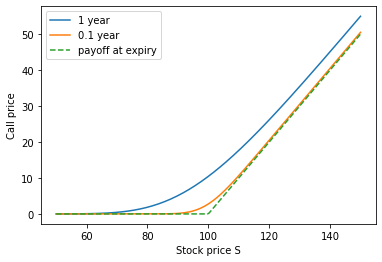

In [3]:
import matplotlib.pyplot as plt

S = np.linspace(50, 150, 200)
plt.plot(S, bs_call(S, 100, 0.05, 0.20, 1.0), label='1 year')
plt.plot(S, bs_call(S, 100, 0.05, 0.20, 0.1), label='0.1 year')
plt.plot(S, np.maximum(S - 100, 0), '--', label='payoff at expiry')
plt.xlabel('Stock price S')
plt.ylabel('Call price')
plt.legend()
plt.show()